## analysis of the fetal health data

In [14]:
# import the libraries
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import warnings 
warnings.filterwarnings('ignore')


In [15]:
#load the dataset
df=pd.read_csv('../data/fetal_health.csv')
df.head()

,baseline value,accelerations,fetal_movement,uterine_contractions,light_decelerations,severe_decelerations,prolongued_decelerations,abnormal_short_term_variability,mean_value_of_short_term_variability,percentage_of_time_with_abnormal_long_term_variability,...,histogram_min,histogram_max,histogram_number_of_peaks,histogram_number_of_zeroes,histogram_mode,histogram_mean,histogram_median,histogram_variance,histogram_tendency,fetal_health
0,120.0,0.000,0.0,0.000,0.000,0.0,0.0,73.0,0.5,43.0,...,62.0,126.0,2.0,0.0,120.0,137.0,121.0,73.0,1.0,2.0
1,132.0,0.006,0.0,0.006,0.003,0.0,0.0,17.0,2.1,0.0,...,68.0,198.0,6.0,1.0,141.0,136.0,140.0,12.0,0.0,1.0
2,133.0,0.003,0.0,0.008,0.003,0.0,0.0,16.0,2.1,0.0,...,68.0,198.0,5.0,1.0,141.0,135.0,138.0,13.0,0.0,1.0
3,134.0,0.003,0.0,0.008,0.003,0.0,0.0,16.0,2.4,0.0,...,53.0,170.0,11.0,0.0,137.0,134.0,137.0,13.0,1.0,1.0
4,132.0,0.007,0.0,0.008,0.000,0.0,0.0,16.0,2.4,0.0,...,53.0,170.0,9.0,0.0,137.0,136.0,138.0,11.0,1.0,1.0


In [16]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2126 entries, 0 to 2125
Data columns (total 22 columns):
 #   Column                                                  Non-Null Count  Dtype  
---  ------                                                  --------------  -----  
 0   baseline value                                          2126 non-null   float64
 1   accelerations                                           2126 non-null   float64
 2   fetal_movement                                          2126 non-null   float64
 3   uterine_contractions                                    2126 non-null   float64
 4   light_decelerations                                     2126 non-null   float64
 5   severe_decelerations                                    2126 non-null   float64
 6   prolongued_decelerations                                2126 non-null   float64
 7   abnormal_short_term_variability                         2126 non-null   float64
 8   mean_value_of_short_term_variability             

In [17]:
print("Missing values per column:")
print(df.isna().sum()[df.isna().sum() > 0] if df.isna().any().any() else "None")

n_dups = df.duplicated().sum()
print(f"\nDuplicate rows: {n_dups}")

Missing values per column:
None

Duplicate rows: 13


In [18]:
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after dropping duplicates:", df.shape)

df.describe().T

Shape after dropping duplicates: (2113, 22)


,count,mean,std,min,25%,50%,75%,max
baseline value,2113.0,133.304780,9.837451,106.0,126.000,133.000,140.000,160.000
accelerations,2113.0,0.003188,0.003871,0.0,0.000,0.002,0.006,0.019
fetal_movement,2113.0,0.009517,0.046804,0.0,0.000,0.000,0.003,0.481
uterine_contractions,2113.0,0.004387,0.002941,0.0,0.002,0.005,0.007,0.015
light_decelerations,2113.0,0.001901,0.002966,0.0,0.000,0.000,0.003,0.015
severe_decelerations,2113.0,0.000003,0.000057,0.0,0.000,0.000,0.000,0.001
prolongued_decelerations,2113.0,0.000159,0.000592,0.0,0.000,0.000,0.000,0.005
abnormal_short_term_variability,2113.0,46.993848,17.177782,12.0,32.000,49.000,61.000,87.000
mean_value_of_short_term_variability,2113.0,1.335021,0.884368,0.2,0.700,1.200,1.700,7.000
percentage_of_time_with_abnormal_long_term_variability,2113.0,9.795078,18.337073,0.0,0.000,0.000,11.000,91.000


In [19]:
TARGET = "fetal_health"
LABELS = {0: "normal", 1: "suspect", 2: "pathological"}
CLASS_NAMES = [LABELS[i] for i in range(3)]

df[TARGET] = df[TARGET].astype(int) - 1
assert set(df[TARGET].unique()) == {0, 1, 2}

FEATURES = [c for c in df.columns if c != TARGET]
print(f"{len(FEATURES)} features")

21 features


## exploratory data analysis

## target distribution 

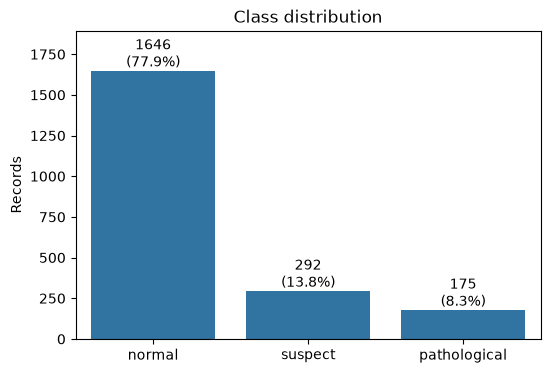

In [20]:
counts = df[TARGET].map(LABELS).value_counts().reindex(CLASS_NAMES)
share = (counts / counts.sum() * 100).round(1)

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=counts.index, y=counts.values, ax=ax)
for i, (c, s) in enumerate(zip(counts.values, share.values)):
    ax.text(i, c, f"{c}\n({s}%)", ha="center", va="bottom")
ax.set_ylabel("Records")
ax.set_xlabel("")
ax.set_title("Class distribution")
ax.set_ylim(0, counts.max() * 1.15)
plt.show()

## feature distribution by class

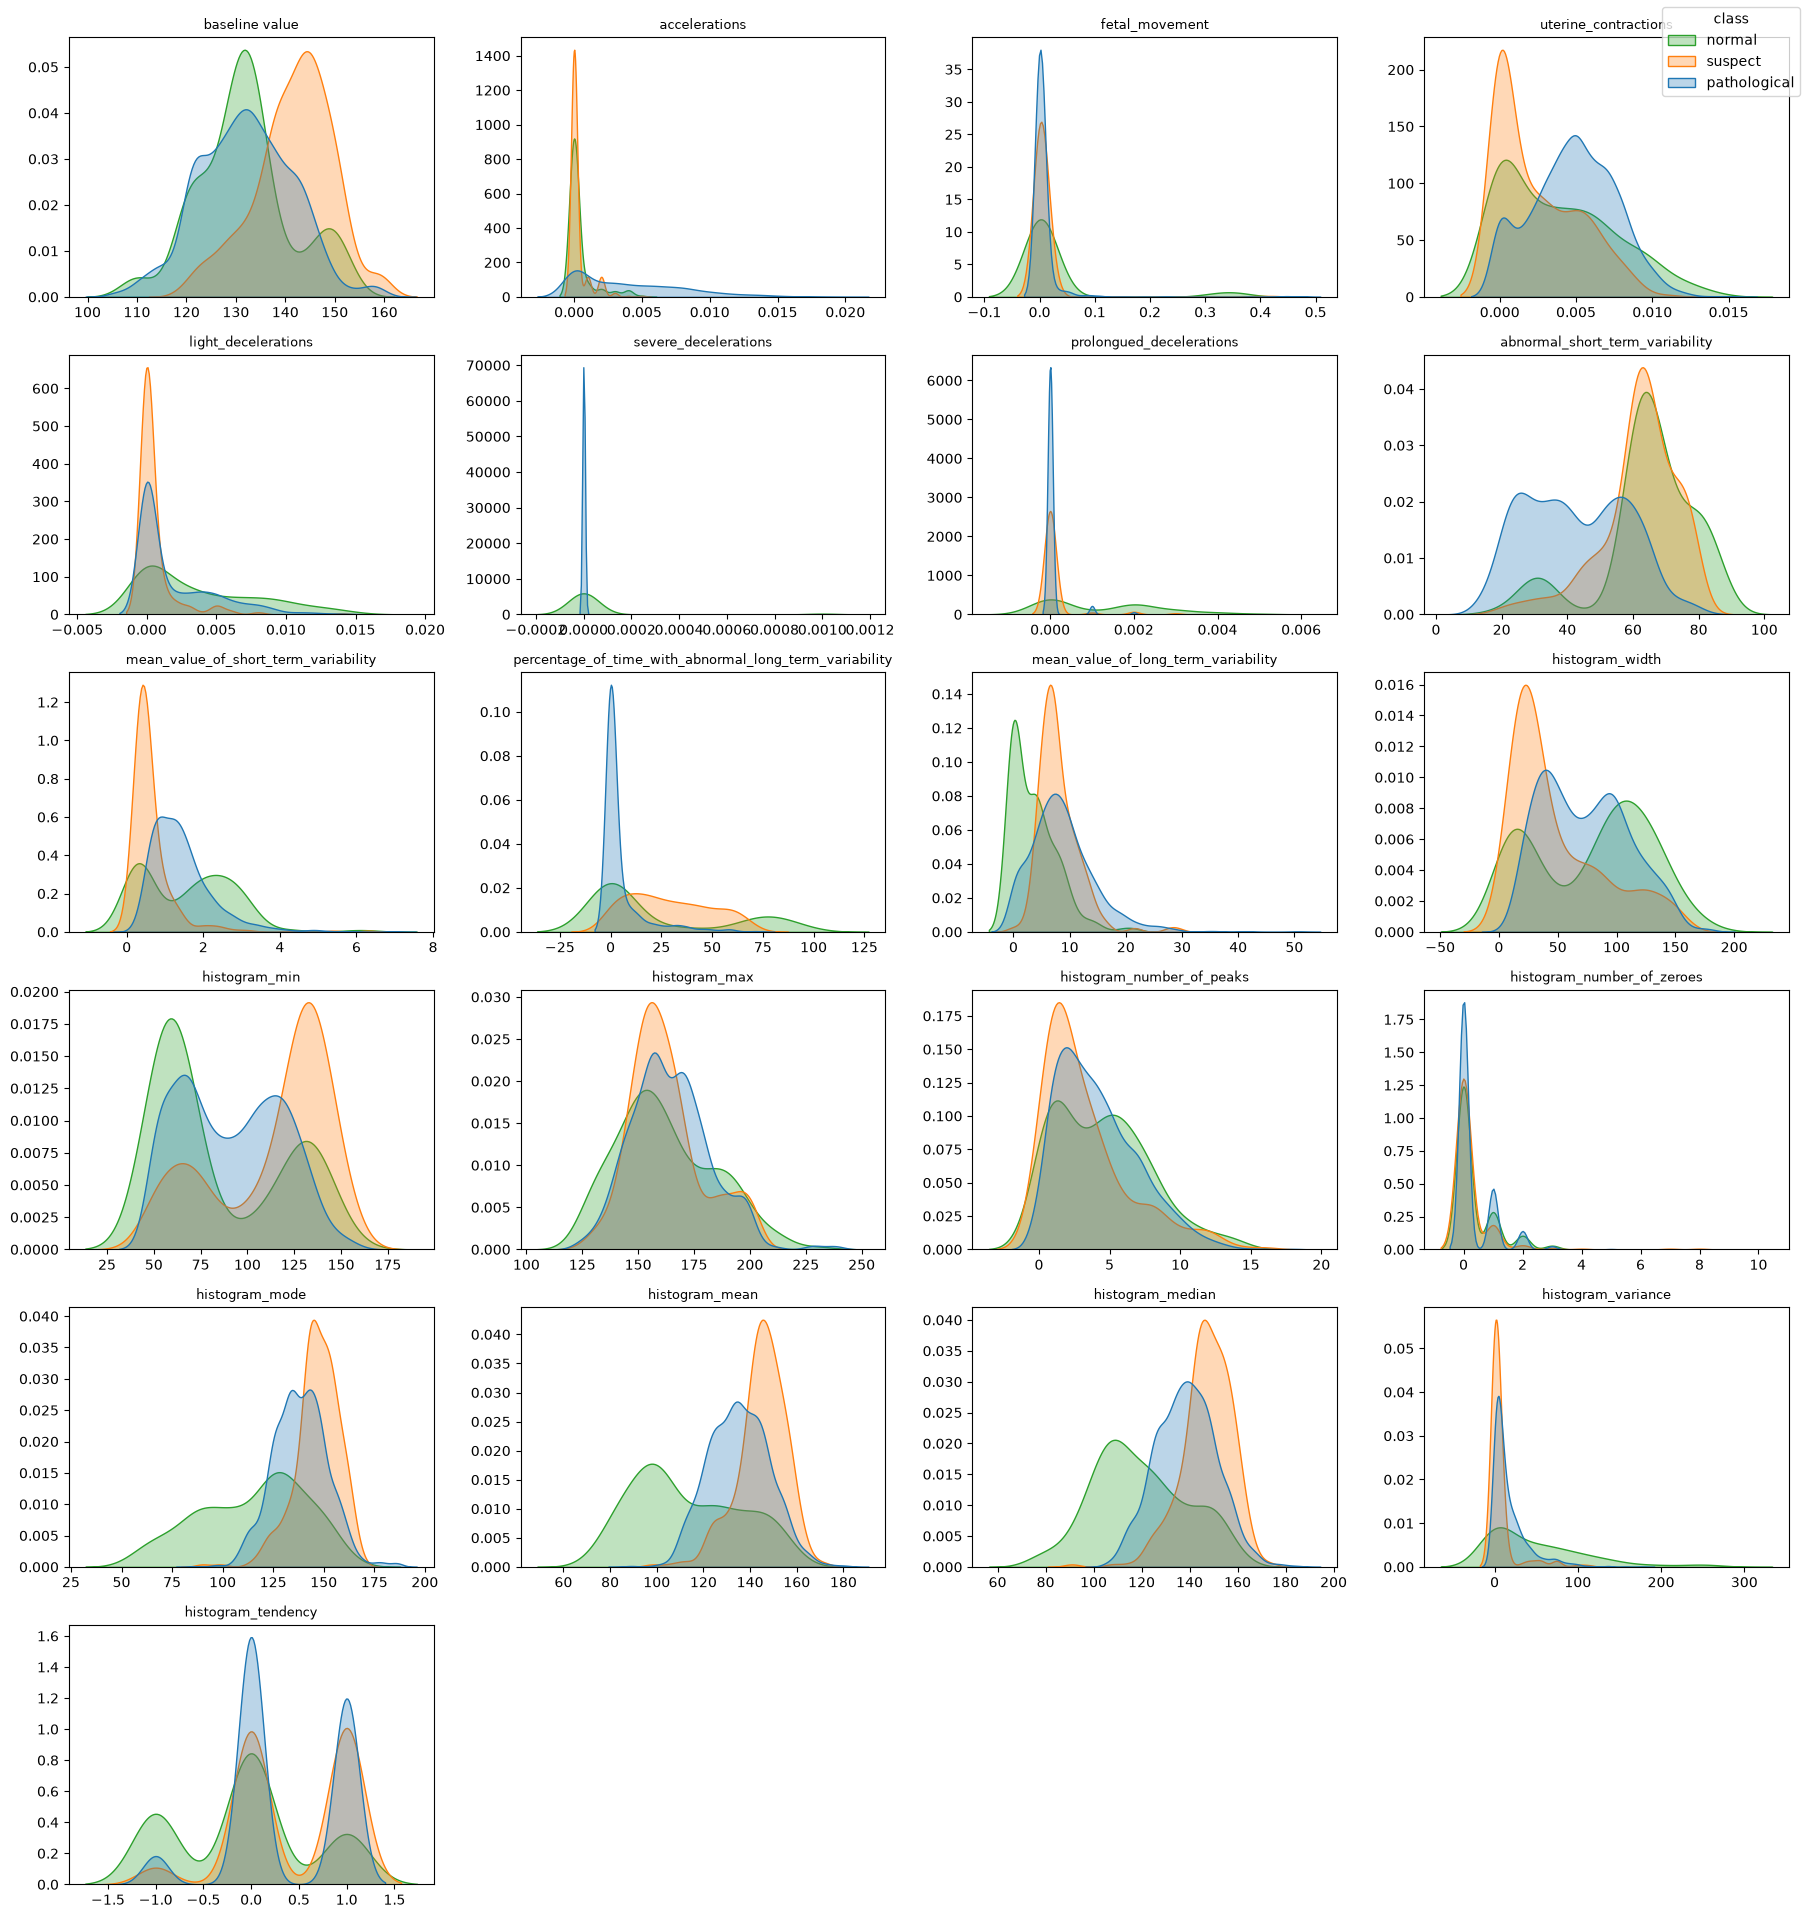

In [21]:
df_plot = df.copy()
df_plot["class"] = df_plot[TARGET].map(LABELS)

n_cols = 4
n_rows = int(np.ceil(len(FEATURES) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 3.2 * n_rows))
for ax, col in zip(axes.ravel(), FEATURES):
    sns.kdeplot(
        data=df_plot, x=col, hue="class", hue_order=CLASS_NAMES,
        common_norm=False, fill=True, alpha=0.3, ax=ax, legend=False,
    )
    ax.set_title(col, fontsize=9)
    ax.set_xlabel("")
    ax.set_ylabel("")
for ax in axes.ravel()[len(FEATURES):]:
    ax.axis("off")
fig.legend(CLASS_NAMES, loc="upper right", title="class")
plt.tight_layout()
plt.show()

## feature mean by class

In [22]:
df.groupby(df[TARGET].map(LABELS))[FEATURES].mean().reindex(CLASS_NAMES).T.round(3)

fetal_health,normal,suspect,pathological
baseline value,131.998,141.651,131.669
accelerations,0.004,0.000,0.000
fetal_movement,0.008,0.008,0.026
uterine_contractions,0.005,0.002,0.004
light_decelerations,0.002,0.001,0.004
severe_decelerations,0.000,0.000,0.000
prolongued_decelerations,0.000,0.000,0.001
abnormal_short_term_variability,42.502,61.791,64.554
mean_value_of_short_term_variability,1.432,0.642,1.582
percentage_of_time_with_abnormal_long_term_variability,5.060,28.832,22.571


## correlation

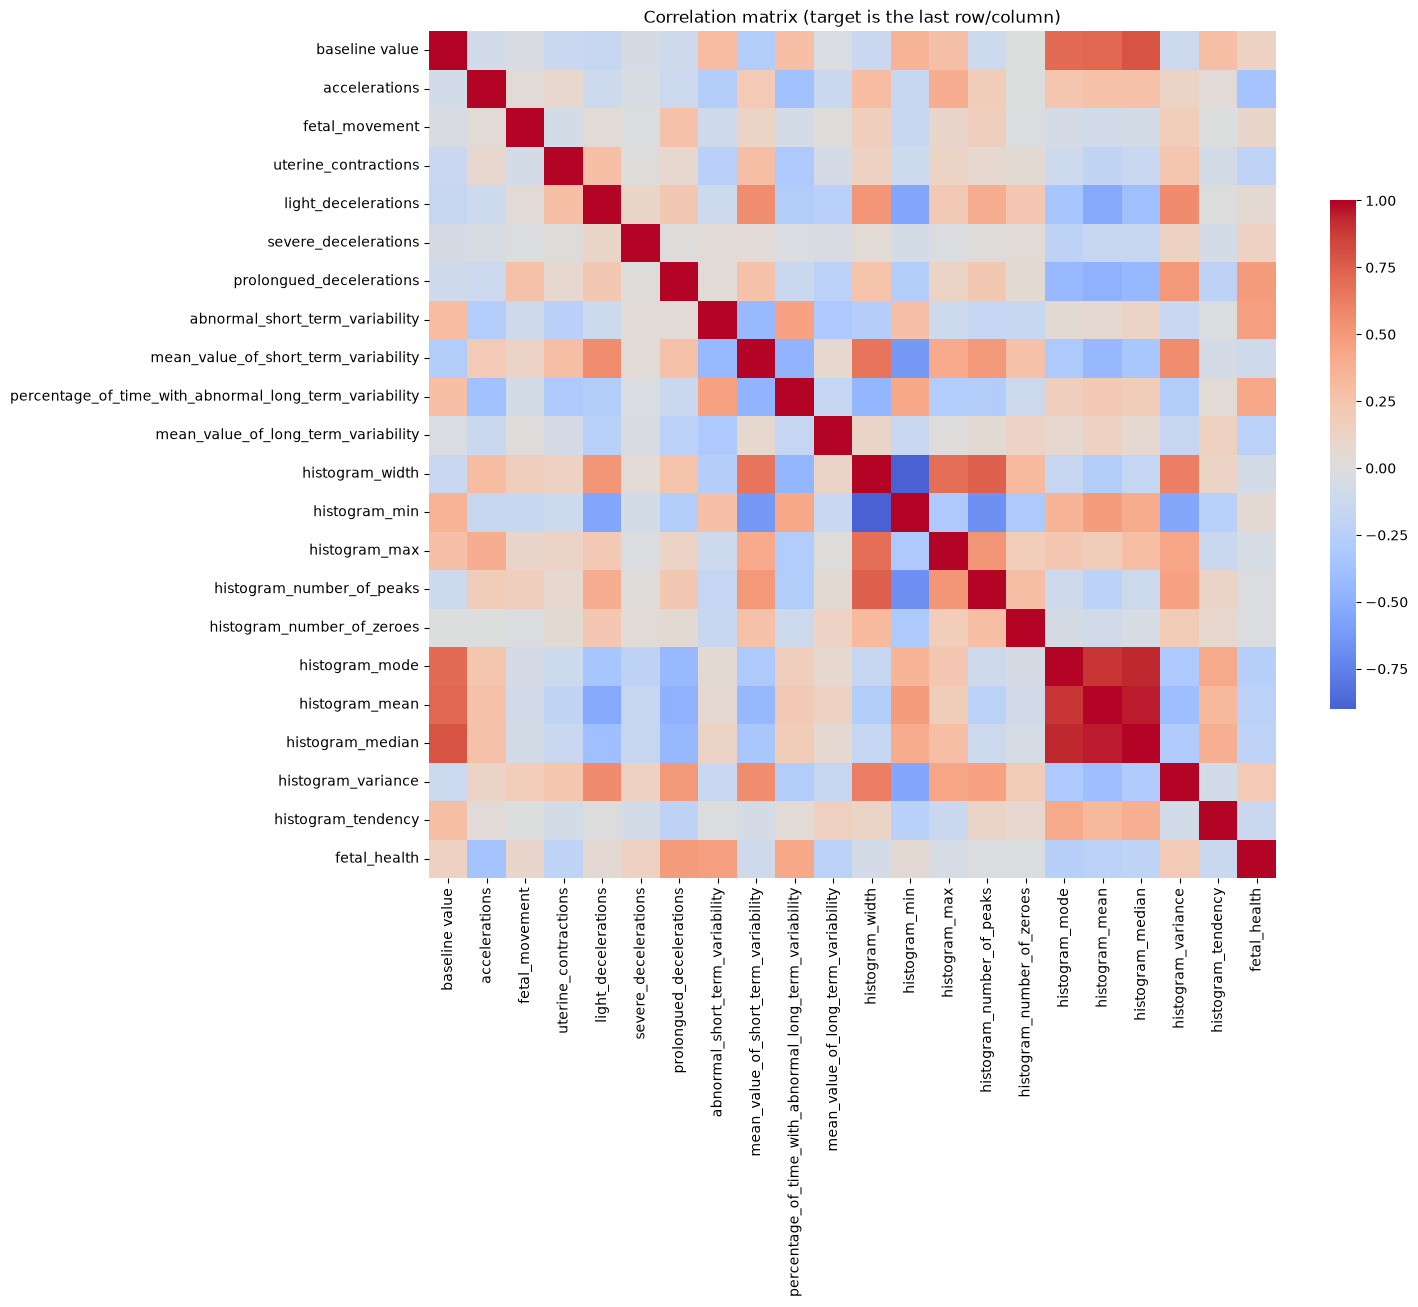

In [23]:
corr = df[FEATURES + [TARGET]].corr()

plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": 0.6})
plt.title("Correlation matrix (target is the last row/column)")
plt.show()

In [24]:
print("Features most correlated with the target (absolute value):")
(corr[TARGET].drop(TARGET).abs().sort_values(ascending=False).head(10).round(3))

Features most correlated with the target (absolute value):


prolongued_decelerations                                  0.487
abnormal_short_term_variability                           0.470
percentage_of_time_with_abnormal_long_term_variability    0.422
accelerations                                             0.364
histogram_mode                                            0.254
histogram_mean                                            0.230
mean_value_of_long_term_variability                       0.226
histogram_median                                          0.208
histogram_variance                                        0.208
uterine_contractions                                      0.205
Name: fetal_health, dtype: float64

In [25]:
# Highly correlated feature pairs (multicollinearity matters for logistic regression)
feat_corr = df[FEATURES].corr().abs()
pairs = (
    feat_corr.where(np.triu(np.ones(feat_corr.shape), k=1).astype(bool))
    .stack()
    .sort_values(ascending=False)
)
pairs[pairs > 0.8].round(3).to_frame("abs_corr")

,,abs_corr
histogram_mean,histogram_median,0.948
histogram_mode,histogram_median,0.933
histogram_width,histogram_min,0.899
histogram_mode,histogram_mean,0.893


## outliers

In [26]:
# Share of values outside 1.5 * IQR per feature
def outlier_share(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean()

(df[FEATURES].apply(outlier_share).sort_values(ascending=False).head(8).mul(100).round(1).to_frame("% outliers"))

,% outliers
histogram_number_of_zeroes,23.8
percentage_of_time_with_abnormal_long_term_variability,14.4
fetal_movement,14.4
histogram_variance,8.7
prolongued_decelerations,8.4
light_decelerations,7.1
histogram_mode,3.5
mean_value_of_long_term_variability,3.4
